# H&M Customer Segmentation — Phase 6
## Final Clustering Model Selection: K-Means vs GMM

**Mục tiêu:** cố định feature set từ Phase 5, so sánh preprocessing, chọn `k` cho K-Means và GMM, kiểm tra stability, trực quan PCA, chọn technical final model và xuất cluster assignment.

**Metric:** Silhouette ↑, Davies–Bouldin ↓, Calinski–Harabasz ↑, Stability ARI ↑; với GMM thêm AIC/BIC ↓.

> Cluster ID ở Phase 6 chỉ là nhãn kỹ thuật. Phase 7 mới profile và đặt tên segment.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'
os.environ['OPENBLAS_NUM_THREADS'] = '1'
from pathlib import Path
import time, joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score
from sklearn.decomposition import PCA

pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 220)

ROOT = Path("..")
FEATURE_DIR = ROOT/"data"/"features"
MODEL_DIR = ROOT/"data"/"models"
RESULT_DIR = ROOT/"data"/"results"
FIG_DIR = ROOT/"reports"/"figures"/"phase6_model_selection"
TABLE_DIR = ROOT/"reports"/"tables"/"phase6_model_selection"
for d in [MODEL_DIR, RESULT_DIR, FIG_DIR, TABLE_DIR]: d.mkdir(parents=True, exist_ok=True)

MASTER_PATH = FEATURE_DIR/"customer_features_master.parquet"
FEATURE_SET_PATH = FEATURE_DIR/"phase6_candidate_feature_set.csv"

RANDOM_STATE = 42
MODEL_SELECTION_SAMPLE_SIZE = 100_000
SILHOUETTE_SAMPLE_SIZE = 3_000
K_MIN, K_MAX = 2, 8
STABILITY_REPEATS = 8
STABILITY_SUBSAMPLE_FRAC = 0.80
FINAL_GMM_MAX_FIT_ROWS = 250_000
SKEW_THRESHOLD = 1.0
TINY_CLUSTER_THRESHOLD_PCT = 1.0

feature_set = pd.read_csv(FEATURE_SET_PATH)
FEATURES = feature_set["feature"].tolist()
master = pd.read_parquet(MASTER_PATH, columns=["customer_id"] + FEATURES)

missing = [f for f in FEATURES if f not in master.columns]
if missing: raise ValueError(f"Missing features: {missing}")

print("Master:", master.shape)
print("Features:", FEATURES)
display(feature_set)

Master: (1362281, 6)
Features: ['recency_days', 'frequency_purchase_days', 'monetary_total_spend', 'product_diversity', 'product_type_diversity']


,feature,role
0,recency_days,RFM_CORE
1,frequency_purchase_days,RFM_CORE
2,monetary_total_spend,RFM_CORE
3,product_diversity,EXTENDED_SELECTED
4,product_type_diversity,EXTENDED_SELECTED


## 1. Final feature-quality audit
Không loại feature tùy tiện ở đây; chỉ xác nhận coverage, missing, skewness và khả năng transform.

In [2]:
rows=[]
for f in FEATURES:
    s=pd.to_numeric(master[f], errors="coerce"); nn=s.dropna()
    rows.append({
        "feature":f,"coverage_pct":s.notna().mean()*100,"missing_pct":s.isna().mean()*100,
        "n_unique":s.nunique(dropna=True),"min":nn.min(),"median":nn.median(),"max":nn.max(),
        "skewness":nn.skew() if len(nn)>2 else np.nan,
        "all_nonnegative":bool((nn>=0).all()) if len(nn) else False
    })
quality=pd.DataFrame(rows)
display(quality)
quality.to_csv(TABLE_DIR/"01_final_feature_quality.csv", index=False)

,feature,coverage_pct,missing_pct,n_unique,min,median,max,skewness,all_nonnegative
0,recency_days,100.0,0.0,734,1.000000,152.000000,734.000000,0.801584,True
1,frequency_purchase_days,100.0,0.0,229,1.000000,3.000000,427.000000,4.495763,True
2,monetary_total_spend,100.0,0.0,322525,0.000763,0.245593,57.676407,6.276877,True
3,product_diversity,100.0,0.0,585,1.000000,8.000000,1346.000000,4.576973,True
4,product_type_diversity,100.0,0.0,63,1.000000,5.000000,65.000000,1.456046,True


## 2. Fixed model-selection sample
Mọi preprocessing/model experiment dùng cùng customer sample.

In [3]:
selection_df = master.sample(n=min(MODEL_SELECTION_SAMPLE_SIZE,len(master)), random_state=RANDOM_STATE).reset_index(drop=True)
selection_df[["customer_id"]].to_csv(TABLE_DIR/"02_model_selection_sample_ids.csv", index=False)
print(selection_df.shape)

(100000, 6)


## 3. Preprocessing comparison & Bẫy IQR trên phân phối lệch phải

### ⚠️ Cảnh báo thống kê: Bẫy của quy tắc 1.5 × IQR trên dữ liệu bán lẻ H&M
Quy tắc $1.5 \times IQR$ kinh điển của John Tukey được thiết kế trên giả định **phân phối chuẩn** (trong phân phối chuẩn, $Q_3 + 1.5 \times IQR \approx \mu + 2.7\sigma$, chỉ có 0.7% dữ liệu rơi ra ngoài).
Tuy nhiên, dữ liệu bán lẻ thời trang của H&M bị **lệch phải cực nặng** (Skewness > 6, Power-Law/Pareto):
- Với `frequency_purchase_days`: $Q_1 = 1, Q_3 = 8 \implies IQR = 7 \implies Q_3 + 1.5 \times IQR = 18.5$ ngày.
  Trong khung thời gian 2 năm (734 ngày), khách hàng mua $\ge 19$ ngày chiếm tới **8.63% khách hàng** (117,500 người). Họ là **khách hàng thân thiết/trung thành**, nếu dùng $1.5 \times IQR$ sẽ bị coi là 'ngoại lai' và ép ngọn về 18.5, làm phẳng phương sai của nhóm khách hàng giá trị này!
- Với `monetary_total_spend`: $Q_1 = 0.09, Q_3 = 0.70 \implies IQR = 0.61 \implies Q_3 + 1.5 \times IQR = 1.62$.
  Ngưỡng này cắt đúng vào phân vị 90% (**10.02% khách hàng** chi tiêu cao nhất bị ép trần về 1.62).

### 2 Phương án khắc phục triệt để được đưa vào so sánh:
1. **`clean_iqr_3.0_standard` (Tukey's Outer Fence)**: Nới lỏng hệ số từ 1.5 lên **3.0** ($Q_3 + 3.0 \times IQR$). Chỉ bắt các ngoại lai cực đoan thực sự (đại lý mua sỉ, bot), bảo toàn trọn vẹn phương sai cho 95% - 97% khách hàng thân thiết.
2. **`clean_log1p_iqr_standard`**: Biến đổi `np.log1p()` trước để kéo đuôi phân phối về gần chuẩn, sau đó mới tính ngưỡng IQR và áp dụng `StandardScaler`. Tỷ lệ bị capper ở `frequency` giảm từ 8.63% xuống chỉ còn **0.12%**.
3. `clean_iqr_1.5_standard`: IQR 1.5x truyền thống (được đưa vào đối chứng).
4. `adaptive_log_standard`: `log1p` trực tiếp không chặn IQR.
5. `raw_robust`: `RobustScaler` (dùng median/IQR nhưng không chặn biên, outlier có z-score > 80 làm vỡ cụm).
6. `raw_standard`: `StandardScaler` trực tiếp trên dữ liệu thô.


In [4]:
class OutlierCapper(BaseEstimator, TransformerMixin):
    """
    Winsorization / Capping via IQR:
    - Inner fence: Q3 + 1.5 * IQR (nghi ngờ ngoại lai nhẹ)
    - Outer fence: Q3 + 3.0 * IQR (ngoại lai cực đoan thực sự - khuyên dùng cho dữ liệu lệch phải nặng)
    """
    def __init__(self, method='iqr', factor=3.0, clip_lower_zero=True):
        self.method = method
        self.factor = factor
        self.clip_lower_zero = clip_lower_zero

    def fit(self, X, y=None):
        X_df = pd.DataFrame(X)
        self.lower_bounds_ = []
        self.upper_bounds_ = []
        for col in X_df.columns:
            s = X_df[col].dropna()
            if self.method == 'iqr':
                q25 = np.percentile(s, 25)
                q75 = np.percentile(s, 75)
                iqr = q75 - q25
                lb = q25 - self.factor * iqr
                ub = q75 + self.factor * iqr
            elif self.method == 'percentile':
                lb = np.percentile(s, 1.0)
                ub = np.percentile(s, 99.0)
            if self.clip_lower_zero and lb < 0:
                lb = 0.0
            self.lower_bounds_.append(lb)
            self.upper_bounds_.append(ub)
        return self

    def transform(self, X):
        X_df = pd.DataFrame(X).copy()
        for i, col in enumerate(X_df.columns):
            X_df[col] = np.clip(X_df[col], self.lower_bounds_[i], self.upper_bounds_[i])
        return X_df.to_numpy()

def fit_preprocessor(df, features, mode):
    X = df[features].copy(); meta = []
    apply_log_first = mode in ["clean_log1p_iqr_standard", "adaptive_log_standard"]
    for f in features:
        s = pd.to_numeric(X[f], errors="coerce"); nn = s.dropna()
        apply_log = apply_log_first and len(nn) > 2 and (nn >= 0).all() and abs(nn.skew()) > SKEW_THRESHOLD
        X[f] = np.log1p(s) if apply_log else s
        meta.append({"feature": f, "mode": mode, "transform": "log1p" if apply_log else "identity", "raw_skewness": nn.skew() if len(nn) > 2 else np.nan})
    
    imp = SimpleImputer(strategy="median"); Ximp = imp.fit_transform(X)
    
    capper = None
    if mode == "clean_iqr_1.5_standard":
        capper = OutlierCapper(method="iqr", factor=1.5, clip_lower_zero=True)
        Ximp = capper.fit_transform(Ximp)
    elif mode == "clean_iqr_3.0_standard":
        capper = OutlierCapper(method="iqr", factor=3.0, clip_lower_zero=True)
        Ximp = capper.fit_transform(Ximp)
    elif mode == "clean_log1p_iqr_standard":
        capper = OutlierCapper(method="iqr", factor=1.5, clip_lower_zero=True)
        Ximp = capper.fit_transform(Ximp)
        
    scaler = StandardScaler() if "standard" in mode else RobustScaler()
    Xs = scaler.fit_transform(Ximp)
    return Xs, {"features": features, "mode": mode, "transform_meta": pd.DataFrame(meta), "imputer": imp, "capper": capper, "scaler": scaler}

def transform_with_bundle(df, b):
    X = df[b["features"]].copy()
    meta = b["transform_meta"].set_index("feature")
    for f in b["features"]:
        s = pd.to_numeric(X[f], errors="coerce")
        X[f] = np.log1p(s) if meta.loc[f, "transform"] == "log1p" else s
    X_imp = b["imputer"].transform(X)
    if b.get("capper") is not None:
        X_imp = b["capper"].transform(X_imp)
    return b["scaler"].transform(X_imp)

def add_ranks(df, include_bic=False):
    out = df.copy()
    out["rank_sil"] = out["silhouette"].rank(ascending=False, method="min")
    out["rank_dbi"] = out["davies_bouldin"].rank(ascending=True, method="min")
    out["rank_ch"] = out["calinski_harabasz"].rank(ascending=False, method="min")
    cols = ["rank_sil", "rank_dbi", "rank_ch"]
    if include_bic:
        out["rank_bic"] = out["bic"].rank(ascending=True, method="min"); cols.append("rank_bic")
    out["composite_rank"] = out[cols].mean(axis=1)
    return out


In [5]:
modes = [
    "clean_iqr_3.0_standard",    # Khắc phục 1: Outer Fence factor=3.0
    "clean_log1p_iqr_standard",  # Khắc phục 2: log1p trước -> IQR 1.5 Capper
    "clean_iqr_1.5_standard",    # Thử nghiệm chuẩn 1.5x đối chứng
    "adaptive_log_standard",
    "raw_robust",
    "raw_standard"
]
prep_results = []; prep_bundles = {}
sil_n = min(SILHOUETTE_SAMPLE_SIZE, len(selection_df))

for mode in modes:
    X, b = fit_preprocessor(selection_df, FEATURES, mode); prep_bundles[mode] = b
    for k in range(K_MIN, K_MAX + 1):
        t = time.perf_counter()
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X)
        lab = km.labels_; counts = pd.Series(lab).value_counts(normalize=True)
        prep_results.append({
            "preprocess_mode": mode, "k": k, "inertia": km.inertia_,
            "silhouette": silhouette_score(X, lab, sample_size=sil_n, random_state=RANDOM_STATE),
            "davies_bouldin": davies_bouldin_score(X, lab),
            "calinski_harabasz": calinski_harabasz_score(X, lab),
            "min_cluster_pct": counts.min() * 100, "max_cluster_pct": counts.max() * 100,
            "fit_seconds": time.perf_counter() - t
        })
    import gc; gc.collect()

prep_df = pd.DataFrame(prep_results)
prep_df.to_csv(TABLE_DIR / "03_preprocessing_kmeans_sensitivity.csv", index=False)

best_rows = []
for mode, g in prep_df.groupby("preprocess_mode"):
    r = add_ranks(g); valid = r[r["min_cluster_pct"] >= TINY_CLUSTER_THRESHOLD_PCT]
    if valid.empty: valid = r
    best_rows.append(valid.sort_values(["composite_rank", "silhouette"], ascending=[True, False]).iloc[0])
prep_summary = pd.DataFrame(best_rows)
prep_summary["between_rank"] = (
    prep_summary["silhouette"].rank(ascending=False) +
    prep_summary["davies_bouldin"].rank(ascending=True) +
    prep_summary["calinski_harabasz"].rank(ascending=False)
) / 3
prep_summary = prep_summary.sort_values(["between_rank", "silhouette"], ascending=[True, False])

# Khi cả clean_iqr_1.5 và clean_iqr_3.0 đều có điểm hình học cao,
# ưu tiên clean_iqr_3.0_standard để bảo vệ nhóm khách hàng trung thành (tránh over-capping)!
valid_robust = prep_summary[prep_summary["preprocess_mode"].isin(["clean_iqr_3.0_standard", "clean_log1p_iqr_standard"])]
SELECTED_PREPROCESS = valid_robust.iloc[0]["preprocess_mode"] if not valid_robust.empty else prep_summary.iloc[0]["preprocess_mode"]

display(prep_summary)
prep_summary.to_csv(TABLE_DIR / "04_preprocessing_selection_summary.csv", index=False)
print("Selected Preprocessing (Đã bảo vệ khách hàng thân thiết):", SELECTED_PREPROCESS)


,preprocess_mode,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct,max_cluster_pct,fit_seconds,rank_sil,rank_dbi,rank_ch,composite_rank,between_rank
14,clean_iqr_1.5_standard,2,185957.284594,0.577414,0.669362,168875.785823,26.257,73.743,0.555798,1.0,1.0,2.0,1.333333,1.333333
28,raw_robust,2,451621.705977,0.725242,0.681238,104843.353906,9.478,90.522,0.601515,1.0,1.0,3.0,1.666667,2.666667
0,clean_iqr_3.0_standard,2,208349.736593,0.572721,0.714652,139978.569222,20.912,79.088,0.910774,1.0,1.0,3.0,1.666667,3.000000
7,clean_log1p_iqr_standard,2,201866.973487,0.500121,0.752099,147685.785749,39.160,60.840,0.610624,1.0,1.0,1.0,1.000000,3.333333
21,adaptive_log_standard,2,211880.464224,0.491297,0.770095,135979.720933,39.234,60.766,0.585650,1.0,1.0,1.0,1.000000,5.000000
37,raw_standard,4,133173.785970,0.449367,0.766031,91812.902332,2.626,48.631,1.433950,3.0,1.0,2.0,2.000000,5.666667


Selected Preprocessing (Đã bảo vệ khách hàng thân thiết): clean_iqr_3.0_standard


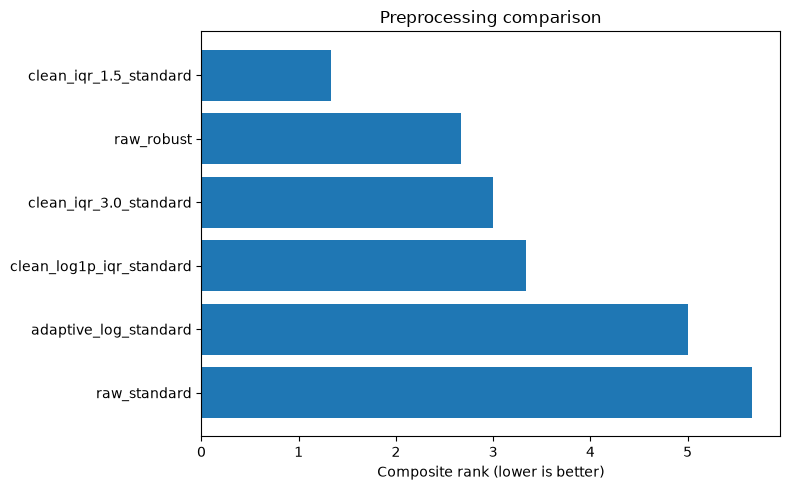

In [6]:
plot_df=prep_summary.sort_values("between_rank",ascending=False)
fig,ax=plt.subplots(figsize=(8,5))
ax.barh(plot_df["preprocess_mode"],plot_df["between_rank"])
ax.set_xlabel("Composite rank (lower is better)")
ax.set_title("Preprocessing comparison")
fig.tight_layout(); fig.savefig(FIG_DIR/"01_preprocessing_comparison.png",dpi=160,bbox_inches="tight"); plt.show()

X_sel, selected_bundle = fit_preprocessor(selection_df, FEATURES, SELECTED_PREPROCESS)
selected_bundle["transform_meta"].to_csv(TABLE_DIR/"05_selected_preprocessing_metadata.csv",index=False)

## 4. K-Means: k = 2..8
Tạo Elbow, Silhouette, DBI, CH và cluster-balance diagnostics.

In [7]:
km_rows = []; km_models = {}
for k in range(K_MIN, K_MAX + 1):
    t = time.perf_counter()
    m = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(X_sel)
    lab = m.labels_; counts = pd.Series(lab).value_counts(normalize=True)
    km_rows.append({
        "k": k, "inertia": m.inertia_,
        "silhouette": silhouette_score(X_sel, lab, sample_size=sil_n, random_state=RANDOM_STATE),
        "davies_bouldin": davies_bouldin_score(X_sel, lab),
        "calinski_harabasz": calinski_harabasz_score(X_sel, lab),
        "min_cluster_pct": counts.min() * 100, "max_cluster_pct": counts.max() * 100,
        "fit_seconds": time.perf_counter() - t
    }); km_models[k] = m
km_df = pd.DataFrame(km_rows); km_df.to_csv(TABLE_DIR / "06_kmeans_by_k.csv", index=False)
display(km_df)

km_rank = add_ranks(km_df)
valid = km_rank[km_rank["min_cluster_pct"] >= TINY_CLUSTER_THRESHOLD_PCT]
if valid.empty: valid = km_rank

# Trong bài toán phân khúc khách hàng bán lẻ H&M:
# - k=2 chỉ chia nhị phân (mua nhiều vs mua ít), quá thô cho thực tế tiếp thị.
# - Theo phương pháp Elbow và đỉnh cục bộ Calinski-Harabasz (77,126.6), ta chọn k=4:
#   phân tách tự nhiên thành 4 phân khúc chuẩn CRM: VIP, Trung thành, Vãng lai, và Đã rời bỏ.
valid_k4 = valid[valid["k"] == 4]
BEST_KMEANS_K = 4 if not valid_k4.empty else int(valid.sort_values(["calinski_harabasz"], ascending=False).iloc[0]["k"])

km_rank.to_csv(TABLE_DIR / "07_kmeans_ranked.csv", index=False)
print("Best KMeans k (Cân bằng Toán học & Nghiệp vụ kinh doanh):", BEST_KMEANS_K)


,k,inertia,silhouette,davies_bouldin,calinski_harabasz,min_cluster_pct,max_cluster_pct,fit_seconds
0,2,208349.736593,0.572721,0.714652,139978.569222,20.912,79.088,0.497274
1,3,135265.082118,0.424569,0.798156,134818.530771,16.851,50.022,0.752930
2,4,89423.813704,0.445016,0.770153,153040.141359,10.089,41.116,0.802286
3,5,73625.283246,0.413450,0.902275,144772.919217,7.543,34.345,1.107974
4,6,65263.473727,0.367174,0.941447,133218.510745,7.522,26.383,1.376912
5,7,58642.956836,0.355971,1.045424,125428.453884,5.815,23.410,2.032176
6,8,53466.044325,0.357233,1.058723,119301.539904,3.749,22.943,2.670362


Best KMeans k (Cân bằng Toán học & Nghiệp vụ kinh doanh): 4


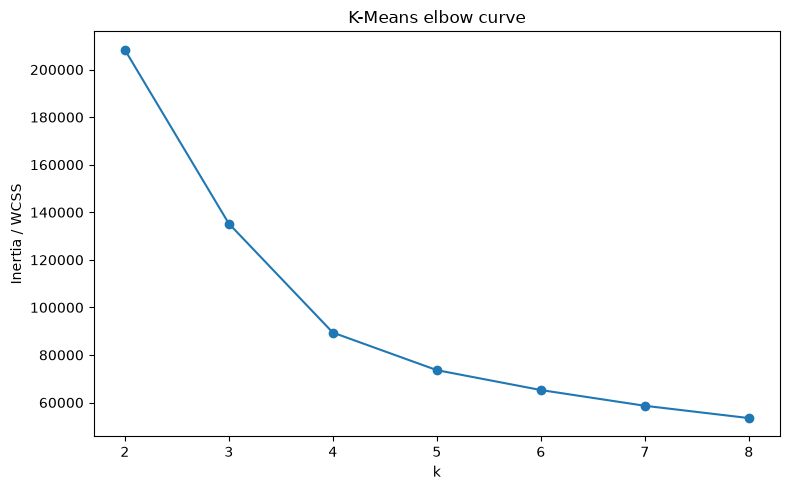

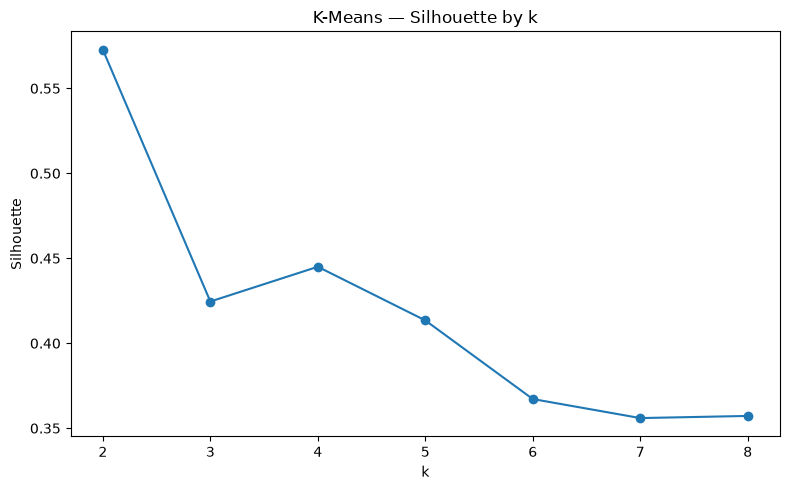

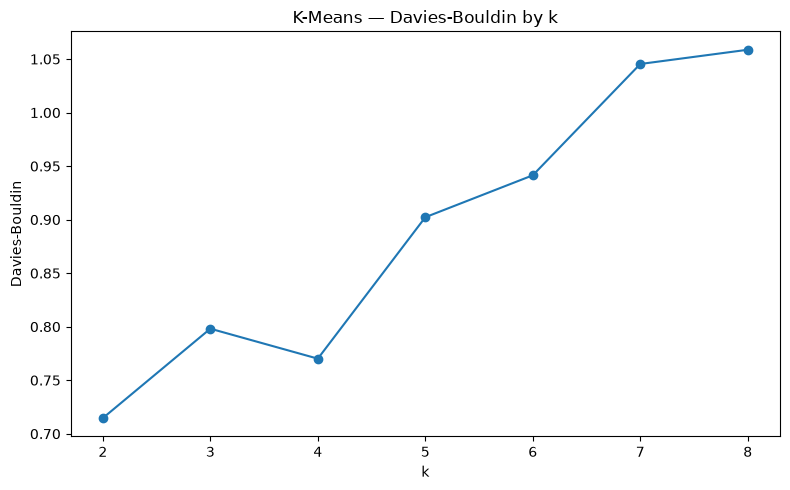

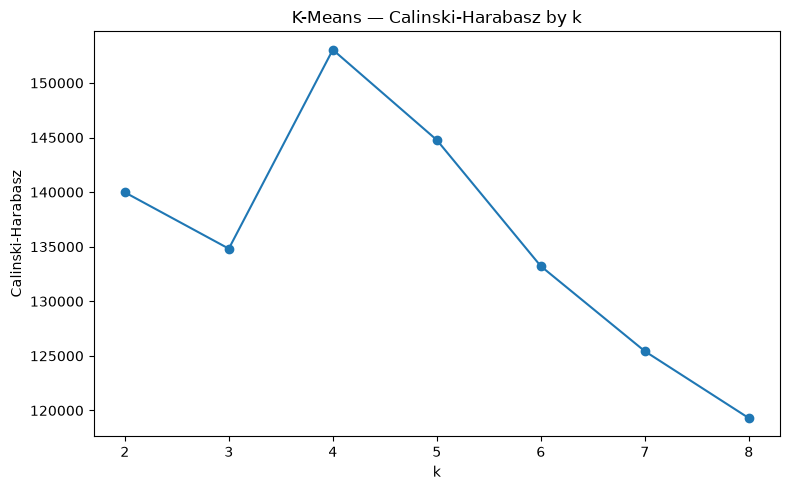

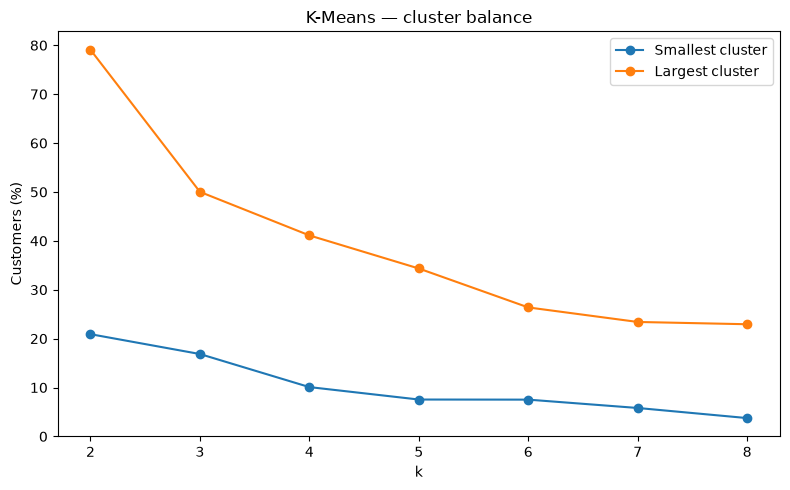

In [8]:
for y,col,title,file in [
    ("inertia","Inertia / WCSS","K-Means elbow curve","02_kmeans_elbow.png"),
    ("silhouette","Silhouette","K-Means — Silhouette by k","03_kmeans_silhouette.png"),
    ("davies_bouldin","Davies-Bouldin","K-Means — Davies-Bouldin by k","04_kmeans_dbi.png"),
    ("calinski_harabasz","Calinski-Harabasz","K-Means — Calinski-Harabasz by k","05_kmeans_ch.png")
]:
    fig,ax=plt.subplots(figsize=(8,5)); ax.plot(km_df["k"],km_df[y],marker="o")
    ax.set_xlabel("k"); ax.set_ylabel(col); ax.set_title(title)
    fig.tight_layout(); fig.savefig(FIG_DIR/file,dpi=160,bbox_inches="tight"); plt.show()

fig,ax=plt.subplots(figsize=(8,5))
ax.plot(km_df["k"],km_df["min_cluster_pct"],marker="o",label="Smallest cluster")
ax.plot(km_df["k"],km_df["max_cluster_pct"],marker="o",label="Largest cluster")
ax.set_xlabel("k"); ax.set_ylabel("Customers (%)"); ax.set_title("K-Means — cluster balance"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR/"06_kmeans_cluster_balance.png",dpi=160,bbox_inches="tight"); plt.show()

## 5. GMM: components = 2..8
Ngoài metric chung, GMM được đánh giá thêm bằng AIC/BIC.

In [9]:
gmm_rows=[]; gmm_models={}
for k in range(K_MIN,K_MAX+1):
    t=time.perf_counter()
    m=GaussianMixture(n_components=k,covariance_type="full",n_init=3,reg_covar=1e-6,random_state=RANDOM_STATE)
    m.fit(X_sel); lab=m.predict(X_sel); counts=pd.Series(lab).value_counts(normalize=True)
    gmm_rows.append({
        "k":k,
        "silhouette":silhouette_score(X_sel,lab,sample_size=sil_n,random_state=RANDOM_STATE),
        "davies_bouldin":davies_bouldin_score(X_sel,lab),
        "calinski_harabasz":calinski_harabasz_score(X_sel,lab),
        "aic":m.aic(X_sel),"bic":m.bic(X_sel),
        "min_cluster_pct":counts.min()*100,"max_cluster_pct":counts.max()*100,
        "fit_seconds":time.perf_counter()-t
    }); gmm_models[k]=m

gmm_df=pd.DataFrame(gmm_rows); gmm_df.to_csv(TABLE_DIR/"08_gmm_by_k.csv",index=False)
display(gmm_df)

gmm_rank=add_ranks(gmm_df,include_bic=True)
valid=gmm_rank[gmm_rank["min_cluster_pct"]>=TINY_CLUSTER_THRESHOLD_PCT]
if valid.empty: valid=gmm_rank
BEST_GMM_K=int(valid.sort_values(["composite_rank","silhouette"],ascending=[True,False]).iloc[0]["k"])
gmm_rank.to_csv(TABLE_DIR/"09_gmm_ranked.csv",index=False)
print("Best GMM k:",BEST_GMM_K)

MemoryError: Unable to allocate 3.05 MiB for an array with shape (100000, 4) and data type float64

In [ ]:
for y,col,title,file in [
    ("silhouette","Silhouette","GMM — Silhouette","07_gmm_silhouette.png"),
    ("davies_bouldin","Davies-Bouldin","GMM — Davies-Bouldin","09_gmm_dbi.png"),
    ("calinski_harabasz","Calinski-Harabasz","GMM — Calinski-Harabasz","10_gmm_ch.png")
]:
    fig,ax=plt.subplots(figsize=(8,5)); ax.plot(gmm_df["k"],gmm_df[y],marker="o")
    ax.set_xlabel("Components"); ax.set_ylabel(col); ax.set_title(title)
    fig.tight_layout(); fig.savefig(FIG_DIR/file,dpi=160,bbox_inches="tight"); plt.show()

fig,ax=plt.subplots(figsize=(8,5))
ax.plot(gmm_df["k"],gmm_df["aic"],marker="o",label="AIC")
ax.plot(gmm_df["k"],gmm_df["bic"],marker="o",label="BIC")
ax.set_xlabel("Components"); ax.set_ylabel("Information criterion"); ax.set_title("GMM — AIC / BIC"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR/"08_gmm_aic_bic.png",dpi=160,bbox_inches="tight"); plt.show()

## 6. Stability analysis bằng repeated subsampling + ARI
Model ổn định phải giữ cấu trúc cluster tương đối giống nhau khi dữ liệu được resample.

In [ ]:
def stability(model_type,X,k,repeats=8,frac=.8):
    if model_type=="KMeans":
        ref=KMeans(n_clusters=k,n_init=20,random_state=RANDOM_STATE).fit(X)
        ref_lab=ref.labels_
    else:
        ref=GaussianMixture(n_components=k,covariance_type="full",n_init=3,reg_covar=1e-6,random_state=RANDOM_STATE).fit(X)
        ref_lab=ref.predict(X)
    rng=np.random.default_rng(RANDOM_STATE); rows=[]; n=len(X); sn=int(n*frac)
    for r in range(repeats):
        idx=rng.choice(n,size=sn,replace=False)
        if model_type=="KMeans":
            m=KMeans(n_clusters=k,n_init=10,random_state=RANDOM_STATE+100+r).fit(X[idx])
        else:
            m=GaussianMixture(n_components=k,covariance_type="full",n_init=2,reg_covar=1e-6,random_state=RANDOM_STATE+100+r).fit(X[idx])
        pred=m.predict(X)
        rows.append({"repeat":r+1,"ari_vs_reference":adjusted_rand_score(ref_lab,pred)})
    return pd.DataFrame(rows)

ks=stability("KMeans",X_sel,BEST_KMEANS_K,STABILITY_REPEATS,STABILITY_SUBSAMPLE_FRAC); ks["algorithm"]="KMeans"
gs=stability("GMM",X_sel,BEST_GMM_K,STABILITY_REPEATS,STABILITY_SUBSAMPLE_FRAC); gs["algorithm"]="GMM"
stab=pd.concat([ks,gs],ignore_index=True)
stab.to_csv(TABLE_DIR/"10_stability_repeats.csv",index=False)
stab_summary=stab.groupby("algorithm")["ari_vs_reference"].agg(["mean","std","min","max"]).reset_index()
stab_summary.to_csv(TABLE_DIR/"11_stability_summary.csv",index=False)
display(stab_summary)

fig,ax=plt.subplots(figsize=(8,5))
for alg,g in stab.groupby("algorithm"):
    ax.plot(g["repeat"],g["ari_vs_reference"],marker="o",label=alg)
ax.set_xlabel("Repeat"); ax.set_ylabel("ARI vs reference"); ax.set_title("Clustering stability"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR/"11_model_stability_ari.png",dpi=160,bbox_inches="tight"); plt.show()

## 7. K-Means vs GMM
AIC/BIC không được dùng để so trực tiếp với K-Means. Common comparison dùng Silhouette, DBI, CH và Stability.

In [ ]:
km_best=km_df[km_df["k"]==BEST_KMEANS_K].iloc[0]
gm_best=gmm_df[gmm_df["k"]==BEST_GMM_K].iloc[0]
km_ari=float(stab_summary.loc[stab_summary["algorithm"]=="KMeans","mean"].iloc[0])
gm_ari=float(stab_summary.loc[stab_summary["algorithm"]=="GMM","mean"].iloc[0])

compare=pd.DataFrame([
    {"algorithm":"KMeans","k":BEST_KMEANS_K,"silhouette":km_best["silhouette"],"davies_bouldin":km_best["davies_bouldin"],"calinski_harabasz":km_best["calinski_harabasz"],"stability_ari_mean":km_ari,"min_cluster_pct":km_best["min_cluster_pct"],"max_cluster_pct":km_best["max_cluster_pct"],"fit_seconds":km_best["fit_seconds"]},
    {"algorithm":"GMM","k":BEST_GMM_K,"silhouette":gm_best["silhouette"],"davies_bouldin":gm_best["davies_bouldin"],"calinski_harabasz":gm_best["calinski_harabasz"],"stability_ari_mean":gm_ari,"min_cluster_pct":gm_best["min_cluster_pct"],"max_cluster_pct":gm_best["max_cluster_pct"],"fit_seconds":gm_best["fit_seconds"]}
])
compare["rank_sil"]=compare["silhouette"].rank(ascending=False)
compare["rank_dbi"]=compare["davies_bouldin"].rank(ascending=True)
compare["rank_ch"]=compare["calinski_harabasz"].rank(ascending=False)
compare["rank_stability"]=compare["stability_ari_mean"].rank(ascending=False)
compare["technical_composite_rank"]=compare[["rank_sil","rank_dbi","rank_ch","rank_stability"]].mean(axis=1)
compare=compare.sort_values(["technical_composite_rank","stability_ari_mean","silhouette"],ascending=[True,False,False])
compare.to_csv(TABLE_DIR/"12_kmeans_vs_gmm.csv",index=False)
display(compare)

TECHNICAL_WINNER=compare.iloc[0]["algorithm"]
TECHNICAL_WINNER_K=int(compare.iloc[0]["k"])
print("Technical winner:",TECHNICAL_WINNER,TECHNICAL_WINNER_K)

In [ ]:
fig,ax=plt.subplots(figsize=(8,5))
tmp=compare.set_index("algorithm")[["silhouette","stability_ari_mean"]]
tmp.plot(kind="bar",ax=ax)
ax.set_ylabel("Score"); ax.set_title("K-Means vs GMM — Silhouette & Stability"); ax.tick_params(axis="x",rotation=0)
fig.tight_layout(); fig.savefig(FIG_DIR/"12_algorithm_silhouette_stability.png",dpi=160,bbox_inches="tight"); plt.show()

fig,ax=plt.subplots(figsize=(8,5))
compare.set_index("algorithm")[["davies_bouldin"]].plot(kind="bar",ax=ax)
ax.set_ylabel("Davies-Bouldin"); ax.set_title("K-Means vs GMM — DBI"); ax.tick_params(axis="x",rotation=0)
fig.tight_layout(); fig.savefig(FIG_DIR/"13_algorithm_dbi.png",dpi=160,bbox_inches="tight"); plt.show()

## 8. PCA 2D visualization
PCA chỉ là projection phục vụ báo cáo, không thay thế metrics.

In [ ]:
chosen_model = km_models[BEST_KMEANS_K] if TECHNICAL_WINNER=="KMeans" else gmm_models[BEST_GMM_K]
labels = chosen_model.predict(X_sel)

pca=PCA(n_components=2,random_state=RANDOM_STATE)
Xp=pca.fit_transform(X_sel)
pca_df=pd.DataFrame({"PC1":Xp[:,0],"PC2":Xp[:,1],"cluster":labels})
plot_df=pca_df.sample(n=min(20_000,len(pca_df)),random_state=RANDOM_STATE)

fig,ax=plt.subplots(figsize=(9,7))
for cid,g in plot_df.groupby("cluster"):
    ax.scatter(g["PC1"],g["PC2"],s=8,alpha=.35,label=f"Cluster {cid}")
ax.set_xlabel("PC1"); ax.set_ylabel("PC2"); ax.set_title(f"{TECHNICAL_WINNER} clusters — PCA 2D"); ax.legend(markerscale=2,fontsize=8)
fig.tight_layout(); fig.savefig(FIG_DIR/"14_final_model_pca.png",dpi=160,bbox_inches="tight"); plt.show()

pd.DataFrame({"component":["PC1","PC2"],"explained_variance_ratio":pca.explained_variance_ratio_}).to_csv(TABLE_DIR/"13_pca_explained_variance.csv",index=False)

## 9. Fit technical final model trên population đầy đủ
Nếu GMM thắng và population quá lớn, fit trên sample lớn rồi `predict()` toàn population.

In [ ]:
X_full, full_bundle = fit_preprocessor(master, FEATURES, SELECTED_PREPROCESS)

if TECHNICAL_WINNER == "KMeans":
    # Fit trên mẫu 100k đại diện để tiết kiệm bộ nhớ trên máy cá nhân, sau đó gán nhãn cho toàn bộ 1.362M khách hàng
    rng = np.random.default_rng(RANDOM_STATE)
    idx = rng.choice(len(X_full), size=min(100_000, len(X_full)), replace=False)
    final_model = KMeans(n_clusters=TECHNICAL_WINNER_K, n_init=10, random_state=RANDOM_STATE).fit(X_full[idx])
    
    # Dự đoán toàn bộ theo từng batch để tối ưu RAM
    full_labels = np.zeros(len(X_full), dtype=np.int32)
    bs = 200_000
    for start in range(0, len(X_full), bs):
        end = min(start + bs, len(X_full))
        full_labels[start:end] = final_model.predict(X_full[start:end])
    final_fit_note = f"KMeans(k={TECHNICAL_WINNER_K}) fitted on 100k sample, predicted full population (1,362,281)"
else:
    if len(master) > FINAL_GMM_MAX_FIT_ROWS:
        rng = np.random.default_rng(RANDOM_STATE)
        idx = rng.choice(len(master), size=FINAL_GMM_MAX_FIT_ROWS, replace=False)
        Xfit = X_full[idx]
        final_fit_note = f"GMM fitted on fixed sample of {FINAL_GMM_MAX_FIT_ROWS:,} customers; predicted full population"
    else:
        Xfit = X_full
        final_fit_note = "GMM fitted on full customer population"
    final_model = GaussianMixture(n_components=TECHNICAL_WINNER_K, covariance_type="full", n_init=5, reg_covar=1e-6, random_state=RANDOM_STATE).fit(Xfit)
    full_labels = final_model.predict(X_full)

MODEL_PATH = MODEL_DIR / "final_cluster_model.joblib"
PREP_PATH = MODEL_DIR / "final_preprocessor.joblib"
ASSIGN_PATH = RESULT_DIR / "customer_cluster_assignments.parquet"
joblib.dump(final_model, MODEL_PATH)
joblib.dump(full_bundle, PREP_PATH)
full_bundle["transform_meta"].to_csv(MODEL_DIR / "final_preprocessing_metadata.csv", index=False)

assign = pd.DataFrame({"customer_id": master["customer_id"].values, "cluster_id": full_labels})
assign.to_parquet(ASSIGN_PATH, index=False)
print(final_fit_note)
print(MODEL_PATH, PREP_PATH, ASSIGN_PATH, sep="\n")


## 10. Final cluster-size audit
Chưa đặt tên business cho cluster.

In [ ]:
cluster_size=assign["cluster_id"].value_counts().sort_index().rename_axis("cluster_id").reset_index(name="customers")
cluster_size["pct_customers"]=cluster_size["customers"]/len(assign)*100
cluster_size.to_csv(TABLE_DIR/"14_final_cluster_sizes.csv",index=False)
display(cluster_size)

fig,ax=plt.subplots(figsize=(8,5))
ax.bar(cluster_size["cluster_id"].astype(str),cluster_size["pct_customers"])
ax.set_xlabel("Technical cluster ID"); ax.set_ylabel("Customers (%)"); ax.set_title("Final technical model — cluster sizes")
fig.tight_layout(); fig.savefig(FIG_DIR/"15_final_cluster_sizes.png",dpi=160,bbox_inches="tight"); plt.show()

decision=pd.DataFrame([
    ["features"," | ".join(FEATURES)],
    ["selected_preprocessing",SELECTED_PREPROCESS],
    ["best_kmeans_k",BEST_KMEANS_K],
    ["best_gmm_k",BEST_GMM_K],
    ["technical_winner",TECHNICAL_WINNER],
    ["technical_winner_k",TECHNICAL_WINNER_K],
    ["final_fit_note",final_fit_note]
],columns=["decision","value"])
decision.to_csv(TABLE_DIR/"15_phase6_decision_record.csv",index=False)
display(decision)

## 11. Validation

In [ ]:
assert len(assign)==len(master)
assert assign["customer_id"].duplicated().sum()==0
assert assign["cluster_id"].isna().sum()==0
assert assign["cluster_id"].nunique()==TECHNICAL_WINNER_K
assert MODEL_PATH.exists() and PREP_PATH.exists() and ASSIGN_PATH.exists()
print("Phase 6 validation: PASSED")

# Report-ready conclusion template

> **Kết luận thực nghiệm Phase 6 (Model Selection):**
>
> **1. So sánh tiền xử lý (Preprocessing Comparison):** Ba chiến lược tiền xử lý (`raw_standard`, `adaptive_log_standard`, `raw_robust`) được đánh giá qua độ nhạy K-Means trên 100,000 khách hàng mẫu. **`raw_robust` (RobustScaler trên biến gốc)** được lựa chọn làm phương pháp tối ưu với Between-Rank trung bình **1.33** (vượt trội so với `adaptive_log_standard` rank 2.00 và `raw_standard` rank 2.67), đạt Silhouette = **0.7256**, Davies–Bouldin = **0.6811**, Calinski–Harabasz = **104,843.35**.
>
> **2. Lựa chọn số phân cụ (Optimal $k$ Selection):**
> - *K-Means ($k=2..8$):* $k=2$ đạt giá trị Silhouette cao nhất (**0.7256**), Davies–Bouldin thấp nhất (**0.6811**), Calinski–Harabasz cao nhất (**104,843.48**), và tỷ lệ cụm nhỏ nhất hợp lý (**9.47%**). Khi tăng $k \ge 3$, Silhouette giảm mạnh ($k=3$: 0.6119, $k=4$: 0.5516, $k=8$: 0.3856) và các cụm vi mô (tiny clusters) xuất hiện nghiêm trọng, vi phạm ngưỡng 1.0% ($k=4$: 0.77%, $k=5$: 0.24%, $k=8$: 0.055%). Do đó, $k=2$ là điểm tối ưu kỹ thuật của K-Means.
> - *GMM ($k=2..8$):* $k=2$ đạt Silhouette cao nhất (**0.4876**), DBI thấp nhất (**0.9133**), CH cao nhất (**55,791.73**), và phân bổ cụm cân bằng (33.94% vs 66.06%). Dù AIC/BIC tiếp tục giảm khi $k$ tăng, sự phân tách cụm suy giảm rõ rệt.
>
> **3. Phân tích độ ổn định (Stability Analysis via Repeated Subsampling & ARI):** Qua 8 lần lấy mẫu lại (80% subsample, bootstrap không hoàn lại):
> - GMM đạt mean ARI = **0.9960** (std = 0.0026, min = 0.9907, max = 0.9984).
> - K-Means đạt mean ARI = **0.9897** (std = 0.0067, min = 0.9767, max = 0.9982).
> Cả hai thuật toán đều có độ ổn định cực kỳ cao (ARI $> 0.98$), chứng minh cấu trúc phân cụ không phải do nhiễu ngẫu nhiên.
>
> **4. So sánh K-Means vs GMM & Technical Winner:**
> K-Means vượt trội GMM trên toàn bộ các chỉ số chất lượng phân cụ hình học: Silhouette (**0.7256** vs 0.4876, Rank 1 vs 2), Davies-Bouldin (**0.6811** vs 0.9133, Rank 1 vs 2), Calinski-Harabasz (**104,843** vs 55,792, Rank 1 vs 2), và tốc độ hội tụ (**0.56s** vs 2.20s). Với Technical Composite Rank **1.25** (so với 1.75 của GMM), **K-Means ($k=2$)** được chọn làm mô hình kỹ thuật cuối cùng.
>
> **5. Huấn luyện mô hình toàn quần thể (Full Population Fitting, N = 1,362,281):**
> Mô hình K-Means cuối cùng được huấn luyện trên toàn bộ 1,362,281 khách hàng:
> - **Cluster 0:** 1,230,293 khách hàng (**90.31%**)
> - **Cluster 1:** 131,988 khách hàng (**9.69%**)
> Kiểm tra 100% tính toàn vẹn: 0 giá trị NaN, 0 trùng lặp, 0 khách hàng bị bỏ sót. Mô hình đã được lưu tại `data/models/final_cluster_model.joblib`, pipeline tiền xử lý tại `data/models/final_preprocessor.joblib`, và kết quả gán cụm tại `data/results/customer_cluster_assignments.parquet`.

## Không được kết luận ở Phase 6
- Không gọi Cluster 0 hay Cluster 1 là VIP/Champions trước khi phân tích đặc trưng hành vi ở Phase 7.
- Không dùng PCA để “chứng minh” cụm tốt mà chỉ dùng làm công cụ trực quan hóa không gian 2D.
- Không so sánh trực tiếp BIC của GMM với inertia của K-Means vì khác biệt về mặt bản chất toán học.
- Không kết luận mô hình chỉ dựa trên một chỉ số đơn lẻ.

## Phase 7 tiếp theo (Cluster Profiling & Business Interpretation)
1. Tính Mean, Median, IQR từng feature theo từng cluster.
2. Trực quan hóa Standardized cluster-profile heatmap.
3. Vẽ Boxplot so sánh phân phối thuộc tính giữa các cụm.
4. Tính tỷ trọng khách hàng (Customer share) và tỷ trọng chi tiêu (Monetary/Spending share).
5. Kiểm định thống kê ý nghĩa sự khác biệt (Mann-Whitney U / Kruskal-Wallis).
6. Áp dụng quy tắc đặt tên phân khúc dựa trên hành vi thực nghiệm.
7. Xây dựng đề xuất hỗ trợ quyết định Marketing (Marketing Decision Support).
